In [1]:
"""
Conversão automática da worksheet Mathcad fonte_chaveada_buck.mcdx para Python.

Unidades: os valores são armazenados em SI internamente.
Ex.: tensão em V, corrente em A, indutância em H, capacitância em F.
Os comentários indicam a unidade de apresentação usada no Mathcad quando disponível.
"""
import math
import operator

In [2]:
"""
Dimensionamento do capacitor de filtro de um retificador monofasico
de onda completa, segundo o metodo detalhado de Ivo Barbi
(eqs. 1.69, 1.71 e 1.73 - "Projetos de Fontes Chaveadas").

alpha = pi/2 - asen(Vcmin/Vpk)                                   (1.71)
beta  = pi/2 + atan(-wRC)                                        (1.73)
wRC*(1-cos(alpha)) - beta*cos(beta)/2
      - wRC*cos(beta)*[1 - exp(-(pi-alpha-beta)/wRC)] = 0        (1.69)

Dado Vcmin/Vpk, a eq. (1.69) e resolvida numericamente para wRC = w*R*C.
Isso reproduz a curva da Fig. 1.9 (wRC = f(Vcmin/Vpk)) e permite, a
partir de w e R conhecidos, isolar C.
"""

import numpy as np
from scipy.optimize import brentq
import matplotlib.pyplot as plt


# ---------------------------------------------------------------------------
# Nucleo matematico (eqs. 1.69, 1.71, 1.73)
# ---------------------------------------------------------------------------

def alpha_eq171(Vcmin: float, Vpk: float) -> float:
    """Eq. 1.71 - angulo alpha, funcao somente da razao Vcmin/Vpk."""
    return np.pi / 2 - np.arcsin(Vcmin / Vpk)


def beta_eq173(wRC: float) -> float:
    """Eq. 1.73 - angulo beta, funcao somente de wRC (= w*R*C)."""
    return np.pi / 2 + np.arctan(-wRC)


def residuo_eq169(wRC: float, Vcmin: float, Vpk: float) -> float:
    """
    Eq. 1.69 reescrita como f(wRC) = 0.
    wRC e a incognita; alpha vem de Vcmin/Vpk (eq. 1.71),
    beta vem do proprio wRC (eq. 1.73).
    """
    alpha = alpha_eq171(Vcmin, Vpk)
    beta = beta_eq173(wRC)

    termo1 = wRC * (1 - np.cos(alpha))
    termo2 = beta * np.cos(beta) / 2
    expo = np.exp(-(np.pi - alpha - beta) / wRC)
    termo3 = wRC * np.cos(beta) * (1 - expo)

    return termo1 - termo2 - termo3


def resolver_wRC(Vcmin: float, Vpk: float) -> float:
    """
    Resolve a eq. 1.69 para wRC = w*R*C, dado Vcmin/Vpk.

    A funcao residuo tem, para razoes Vcmin/Vpk baixas, uma raiz
    espuria bem proxima de wRC=0 (fora da regiao fisica de interesse).
    Por isso a busca varre a reta numerica em passos logaritmicos e
    pega a PRIMEIRA transicao de sinal negativo->positivo a partir de
    wRC=0.05, que e a raiz que corresponde a curva da Fig. 1.9.
    """
    grid = np.logspace(np.log10(0.05), np.log10(2000), 4000)
    valores = np.array([residuo_eq169(x, Vcmin, Vpk) for x in grid])

    for i in range(len(grid) - 1):
        if valores[i] < 0 <= valores[i + 1]:
            return brentq(residuo_eq169, grid[i], grid[i + 1],
                           args=(Vcmin, Vpk))

    raise RuntimeError(
        f"Nao foi encontrada raiz fisica para Vcmin/Vpk={Vcmin/Vpk:.4f}"
    )


def calcular_capacitor(Vpk: float, Vcmin: float, omega: float, R: float) -> dict:
    """
    Dados Vpk, Vcmin, omega (rad/s) e R, resolve a eq. 1.69 para wRC
    e retorna o valor do capacitor C, junto com as grandezas intermediarias.
    """
    wRC = resolver_wRC(Vcmin, Vpk)
    C = wRC / (omega * R)

    alpha = alpha_eq171(Vcmin, Vpk)
    beta = beta_eq173(wRC)

    return {
        "Vcmin/Vpk": Vcmin / Vpk,
        "wRC": wRC,
        "alpha_rad": alpha,
        "alpha_deg": np.degrees(alpha),
        "beta_rad": beta,
        "beta_deg": np.degrees(beta),
        "C": C,
        "C_uF": C * 1e6,
    }


def gerar_curva_fig19(razoes=None):
    """Gera a curva wRC = f(Vcmin/Vpk), equivalente a Fig. 1.9 do livro."""
    if razoes is None:
        razoes = np.linspace(0.2, 0.97, 200)

    wRCs = np.array([resolver_wRC(Vcmin=r, Vpk=1.0) for r in razoes])
    return razoes, wRCs


# ---------------------------------------------------------------------------
# Funcao de projeto: entrada com as especificacoes reais do estagio
# ---------------------------------------------------------------------------

def projetar_retificador(
    Pout: float,
    rendimento: float,
    Vac_min: float,
    Vac_max: float,
    f: float,
    V_diodo_forward: float = 0.7,
    ripple: float = 0.10,
    n_diodos_conduzindo: int = 2,
    margem_tensao_diodo: float = 1.0,
    verbose: bool = True,
) -> dict:
    """
    Projeta o retificador de onda completa + capacitor de filtro a
    partir das especificacoes do estagio.

    Parametros
    ----------
    Pout : float
        Potencia de saida que o estagio (retificador+filtro) precisa
        entregar ao conversor seguinte [W].
    rendimento : float
        Rendimento estimado do conversor alimentado pelo barramento
        (usado para refletir a potencia de entrada do retificador).
    Vac_min, Vac_max : float
        Faixa de tensao de entrada da rede, em Vrms.
    f : float
        Frequencia da rede [Hz].
    V_diodo_forward : float
        Queda de tensao direta de UM diodo da ponte [V].
    ripple : float
        Ripple percentual desejado em Vcmin, referenciado ao pico
        retificado (ex.: 0.05 = 5%).
    n_diodos_conduzindo : int
        Numero de diodos em serie conduzindo simultaneamente na ponte
        (2 para ponte completa monofasica).
    margem_tensao_diodo : float
        Margem multiplicativa sobre a tensao reversa de pico para a
        escolha do diodo (ex.: 1.2 = 20% de margem). Use 1.0 para ver
        o valor "cru".
    verbose : bool
        Se True, imprime um relatorio formatado do projeto.

    Retorna
    -------
    dict com todas as grandezas de projeto (potencias, tensoes,
    angulos, capacitor exato pela eq. 1.69 e R equivalente de carga).
    """

    omega = 2 * np.pi * f
    queda_total_diodos = n_diodos_conduzindo * V_diodo_forward

    # --- Potencias ---
    Pin = Pout / rendimento

    # --- Tensoes de pico retificadas (ja descontando a queda nos diodos) ---
    Vpk_min = Vac_min * np.sqrt(2) - queda_total_diodos   # pior caso p/ ripple e C
    Vpk_max = Vac_max * np.sqrt(2) - queda_total_diodos   # usado p/ ref. de tensao

    if Vpk_min <= 0:
        raise ValueError(
            "Vpk_min <= 0: a queda nos diodos esta maior que o proprio "
            "pico de tensao minimo da rede. Confira Vac_min e V_diodo_forward."
        )

    # --- Tensao minima no capacitor, a partir do ripple percentual ---
    Vcmin = Vpk_min * (1 - ripple)
    ripple_absoluto = Vpk_min - Vcmin

    # --- Resistencia de carga equivalente (vista pelo estagio retificador) ---
    Vout_medio = (Vpk_min + Vcmin) / 2
    R = Vout_medio ** 2 / Pin

    # --- Capacitor pelo metodo simplificado (balanco de energia, eq. 1.2/1.3) ---
    C_simplificado = Pin / (f * (Vpk_min ** 2 - Vcmin ** 2))

    # --- Capacitor pelo metodo detalhado (eqs. 1.69/1.71/1.73) ---
    preciso = calcular_capacitor(Vpk=Vpk_min, Vcmin=Vcmin, omega=omega, R=R)

    # --- Corrente media/eficaz aproximadas e tensao reversa do diodo ---
    I_out_medio = Pin / Vout_medio
    V_reversa_diodo = Vpk_max * margem_tensao_diodo

    resultado = {
        "Pin_W": Pin,
        "omega": omega,
        "Vpk_min_V": Vpk_min,
        "Vpk_max_V": Vpk_max,
        "Vcmin_V": Vcmin,
        "ripple_absoluto_V": ripple_absoluto,
        "Vout_medio_V": Vout_medio,
        "R_equivalente_ohm": R,
        "I_out_medio_A": I_out_medio,
        "C_simplificado_uF": C_simplificado * 1e6,
        "C_preciso_uF": preciso["C_uF"],
        "wRC": preciso["wRC"],
        "alpha_deg": preciso["alpha_deg"],
        "beta_deg": preciso["beta_deg"],
        "V_reversa_diodo_V": V_reversa_diodo,
    }

    if verbose:
        print("=" * 60)
        print("PROJETO DO RETIFICADOR + FILTRO CAPACITIVO")
        print("=" * 60)
        print(f"Pin                     : {Pin:10.3f} W")
        print(f"Vpk_min (pior caso)     : {Vpk_min:10.3f} V")
        print(f"Vpk_max                 : {Vpk_max:10.3f} V")
        print(f"Vcmin (ripple {ripple*100:.1f}%)     : {Vcmin:10.3f} V")
        print(f"Ripple absoluto         : {ripple_absoluto:10.3f} V")
        print(f"Vout medio              : {Vout_medio:10.3f} V")
        print(f"R equivalente           : {R:10.3f} ohm")
        print(f"I_out medio             : {I_out_medio:10.4f} A")
        print("-" * 60)
        print(f"C (metodo simplificado) : {C_simplificado*1e6:10.2f} uF")
        print(f"C (metodo preciso 1.69) : {preciso['C_uF']:10.2f} uF")
        print(f"  wRC                   : {preciso['wRC']:10.3f}")
        print(f"  alpha                 : {preciso['alpha_deg']:10.3f} graus")
        print(f"  beta                  : {preciso['beta_deg']:10.3f} graus")
        print("-" * 60)
        print(f"V reversa diodo (c/ margem x{margem_tensao_diodo}): {V_reversa_diodo:10.3f} V")
        print("=" * 60)

    return resultado


if __name__ == "__main__":
    # ---- Projeto real do usuario ----
    resultado = projetar_retificador(
        Pout=5,                # W
        rendimento=0.8,
        Vac_min=202,           # Vrms
        Vac_max=231,           # Vrms
        f=60,                  # Hz
        V_diodo_forward=2.5,   # V (ja considerando a tecnologia de diodo usada)
        ripple=0.10,           # 5%
    )

PROJETO DO RETIFICADOR + FILTRO CAPACITIVO
Pin                     :      6.250 W
Vpk_min (pior caso)     :    280.671 V
Vpk_max                 :    321.683 V
Vcmin (ripple 10.0%)     :    252.604 V
Ripple absoluto         :     28.067 V
Vout medio              :    266.638 V
R equivalente           :  11375.296 ohm
I_out medio             :     0.0234 A
------------------------------------------------------------
C (metodo simplificado) :       6.96 uF
C (metodo preciso 1.69) :       5.91 uF
  wRC                   :     25.350
  alpha                 :     25.842 graus
  beta                  :      2.259 graus
------------------------------------------------------------
V reversa diodo (c/ margem x1.0):    321.683 V


In [3]:
#Projeto do Conv. Buck
Vcmin_ponte = resultado["Vcmin_V"]

Vin_min_buck = Vcmin_ponte #V
Vin_max_buck = resultado["Vpk_max_V"] #V     -> Isso aqui está considerando as quedas de tensão nos diodos

Pout_buck = 5 #W
Rendimento_buck = 0.85
Pin_buck = Pout_buck / Rendimento_buck
Vout = 15 #V
Delta_Vout = 0.01  #%
Delta_iL  = 0.25 #%
fs = 66e3 #Hz
Ro_buck = Vout**2 / Pout_buck
Io_buck = Pout_buck / Vout

print(Vcmin_ponte)
print(Vin_max_buck)

L = (Vout - (Vout**2)/Vin_max_buck)/(fs*Delta_iL*Io_buck)

C = (Vout*(1-Vout/Vin_max_buck))/(8*Vout*Delta_Vout*fs**2*L)
print(f"Corrente Média: {Io_buck:.3f} A")

print(f"Indutor: {L*1e3:.3f} mH")
print(f"Capacitor: {C*1e6:.3f} uF")
print(f"Resistor equivalente: {Ro_buck:.3f} ohm")


252.60402563942873
321.683332908185
Corrente Média: 0.333 A
Indutor: 2.600 mH
Capacitor: 1.052 uF
Resistor equivalente: 45.000 ohm


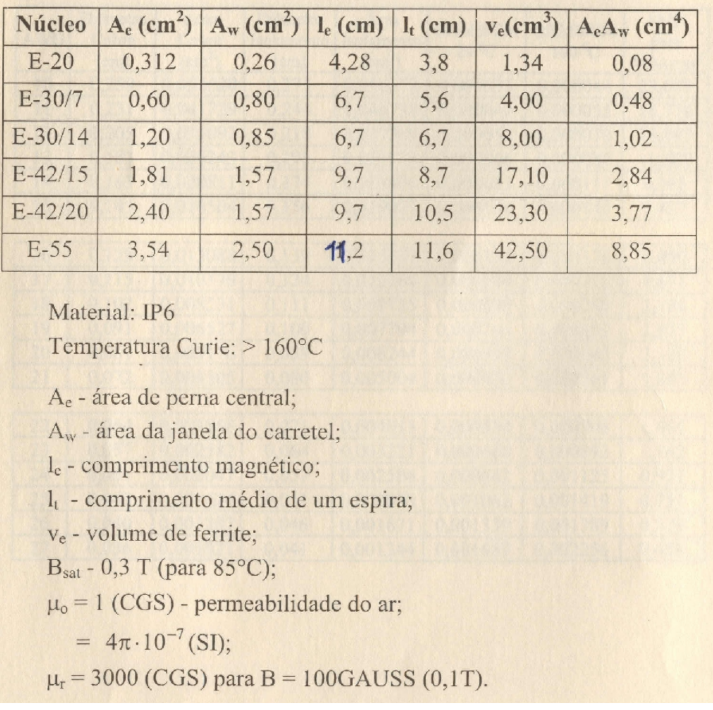

In [71]:
J_max = 450 #A/cm^2   depende do fio de cobre -> apostila disse que é isso tipicamente
Bmax = 0.35 #T  para ferrite
Kw = 0.7   #Fator de Ocupação dos enrolamentos de cobre  -> valor tipico

IL_pico = Io_buck*(1+Delta_iL/2)  #A 
IL_rms = np.sqrt(Io_buck**2 + (Delta_iL*Io_buck/12)**2)
Ae_Aw = L*IL_pico*IL_rms*1e4/(Bmax*J_max*Kw)

print(Ae_Aw)
print(f"IL pico: {IL_pico:.3f} A")
print(f"IL rms: {IL_rms:.3f} A")
print(f"Produto Ae*Aw: {Ae_Aw:.6f} cm^4")


0.029485997643259494
IL pico: 0.375 A
IL rms: 0.333 A
Produto Ae*Aw: 0.029486 cm^4


In [ ]:
import numpy as np

# Identificação dos núcleos
nucleos = np.array([
    "E-20",
    "E-30/7",
    "E-30/14",
    "E-42/15",
    "E-42/20",
    "E-55"
])

# Colunas:
# Ae (cm²), Aw (cm²), le (cm), lt (cm),
# Ve (cm³), AeAw (cm⁴)

dados_nucleos = np.array([
    [0.312, 0.26,  4.28,  3.8,  1.34, 0.08],
    [0.600, 0.80,  6.70,  5.6,  4.00, 0.48],
    [1.200, 0.85,  6.70,  6.7,  8.00, 1.02],
    [1.810, 1.57,  9.70,  8.7, 17.10, 2.84],
    [2.400, 1.57,  9.70, 10.5, 23.30, 3.77],
    [3.540, 2.50, 11.20, 11.6, 42.50, 8.85]
], dtype=float)

# Índices das colunas para facilitar o acesso
AE = 0
AW = 1
LE = 2
LT = 3
VE = 4
AE_AW = 5


(array([0, 1, 2, 3, 4, 5], dtype=int64),)

In [77]:
#Escolha seu nucleo
nucleo_selecionado = "E-20"  # Exemplo, substitua pelo nucleo desejado
#Valor de Ae e Aw do nucleo selecionado
nucleo_index = np.where(nucleos == nucleo_selecionado)[0][0]
Ae_nucleo = dados_nucleos[nucleo_index, AE]  # cm²
print(f"Ae do núcleo {nucleo_selecionado}: {Ae_nucleo:.4f} cm²")
Aw_nucleo = dados_nucleos[nucleo_index, AW]  # cm²
print(f"Aw do núcleo {nucleo_selecionado}: {Aw_nucleo:.4f} cm²")
if(Ae_Aw > Ae_nucleo * Aw_nucleo):
    print(f"Produto Ae*Aw do núcleo {nucleo_selecionado} insuficiente.")
N_voltas = L*IL_pico/(Ae_nucleo*1e-4*Bmax)
print(f"Número de voltas: {N_voltas:.3f}")

Ae do núcleo E-20: 0.3120 cm²
Aw do núcleo E-20: 0.2600 cm²
Número de voltas: 89.289


In [17]:
import numpy as np

# Bitola dos fios
awg = np.arange(10, 42)

# Colunas de dados:
# [diam_cobre_cm, area_cobre_cm2,
#  diam_isolamento_cm, area_isolamento_cm2,
#  R_20C_ohm_cm, R_100C_ohm_cm, corrente_450A_cm2_A]

dados_fios = np.array([
    [0.259, 0.052620, 0.273, 0.058572, 0.000033, 0.000044, 23.679],  # AWG 10
    [0.231, 0.041729, 0.244, 0.046738, 0.000041, 0.000055, 18.778],  # AWG 11
    [0.205, 0.033092, 0.218, 0.037309, 0.000052, 0.000070, 14.892],  # AWG 12
    [0.183, 0.026243, 0.195, 0.029793, 0.000066, 0.000080, 11.809],  # AWG 13
    [0.163, 0.020811, 0.174, 0.023800, 0.000083, 0.000111,  9.365],  # AWG 14
    [0.145, 0.016504, 0.156, 0.019021, 0.000104, 0.000140,  7.427],  # AWG 15
    [0.129, 0.013088, 0.139, 0.015207, 0.000132, 0.000176,  5.890],  # AWG 16
    [0.115, 0.010379, 0.124, 0.012164, 0.000166, 0.000222,  4.671],  # AWG 17
    [0.102, 0.008231, 0.111, 0.009735, 0.000209, 0.000280,  3.704],  # AWG 18
    [0.091, 0.006527, 0.100, 0.007794, 0.000264, 0.000353,  2.937],  # AWG 19
    [0.081, 0.005176, 0.089, 0.006244, 0.000333, 0.000445,  2.329],  # AWG 20
    [0.072, 0.004105, 0.080, 0.005004, 0.000420, 0.000561,  1.847],  # AWG 21
    [0.064, 0.003255, 0.071, 0.004013, 0.000530, 0.000708,  1.465],  # AWG 22
    [0.057, 0.002582, 0.064, 0.003221, 0.000668, 0.000892,  1.162],  # AWG 23
    [0.051, 0.002047, 0.057, 0.002586, 0.000842, 0.001125, 0.921],  # AWG 24
    [0.045, 0.001624, 0.051, 0.002078, 0.001062, 0.001419, 0.731],  # AWG 25
    [0.040, 0.001287, 0.046, 0.001671, 0.001339, 0.001789, 0.579],  # AWG 26
    [0.036, 0.001021, 0.041, 0.001344, 0.001689, 0.002256, 0.459],  # AWG 27
    [0.032, 0.000810, 0.037, 0.001083, 0.002129, 0.002845, 0.364],  # AWG 28
    [0.029, 0.000642, 0.033, 0.000872, 0.002685, 0.003587, 0.289],  # AWG 29
    [0.025, 0.000509, 0.030, 0.000704, 0.003386, 0.004523, 0.229],  # AWG 30
    [0.023, 0.000404, 0.027, 0.000568, 0.004269, 0.005704, 0.182],  # AWG 31
    [0.020, 0.000320, 0.024, 0.000459, 0.005384, 0.007192, 0.144],  # AWG 32
    [0.018, 0.000254, 0.022, 0.000371, 0.006789, 0.009070, 0.114],  # AWG 33
    [0.016, 0.000201, 0.020, 0.000300, 0.008560, 0.011437, 0.091],  # AWG 34
    [0.014, 0.000160, 0.018, 0.000243, 0.010795, 0.014422, 0.072],  # AWG 35
    [0.013, 0.000127, 0.016, 0.000197, 0.013612, 0.018186, 0.057],  # AWG 36
    [0.011, 0.000100, 0.014, 0.000160, 0.017165, 0.022932, 0.045],  # AWG 37
    [0.010, 0.000080, 0.013, 0.000130, 0.021644, 0.028917, 0.036],  # AWG 38
    [0.009, 0.000063, 0.012, 0.000106, 0.027293, 0.036464, 0.028],  # AWG 39
    [0.008, 0.000050, 0.010, 0.000086, 0.034417, 0.045981, 0.023],  # AWG 40
    [0.007, 0.000040, 0.009, 0.000070, 0.043399, 0.057982, 0.018],  # AWG 41
], dtype=float)


# Índices das colunas para facilitar o acesso
DIAM_COBRE = 0
AREA_COBRE = 1
DIAM_ISOLAMENTO = 2
AREA_ISOLAMENTO = 3
R_20C = 4
R_100C = 5
CORRENTE_450 = 6

In [ ]:
#Caracteristicas do seu fio de cobre
diametro_max_fio = 15/(np.sqrt(fs))   #Diametro maximo que o condutor devera apresentar em cm
Area_max_fio = np.pi*(diametro_max_fio/2)**2  #cm^2  -> Área MAXIMA do fio de cobre para suportar a corrente IL_rms com densidade J_max

S_fio = IL_rms/J_max  #cm^2  -> Área MINIMA do fio de cobre para suportar a corrente IL_rms com densidade J_max

print(f"Diametro maximo do fio: {diametro_max_fio:.3f} cm")
print(f"Área máxima do fio: {Area_max_fio:.7f} cm^2")
print(f"Área mínima do fio: {S_fio:.7f} cm^2")


Diametro maximo do fio: 0.058 cm
Área máxima do fio: 0.0026775 cm^2
Área mínima do fio: 0.0007409 cm^2


In [63]:
#Escolha seu fio de cobre (AWG) e veja se ele atende as especificações de diametro e área necessaria
#Ex: AWG 40 
A__cobre_fio_awg = dados_fios[awg == 25, AREA_COBRE][0]
A_fio_awg = dados_fios[awg == 25, AREA_ISOLAMENTO][0]
print(f"Área de cobre do fio AWG: {A__cobre_fio_awg:.7f} cm^2")
print(f"\nÁrea de isolamento do fio AWG: {A_fio_awg:.7f} cm^2")


if(A__cobre_fio_awg > Area_max_fio):
    print(f"\nFio AWG 25 atende a restrição de diametro maximo do condutor.")

#Quantidade de fios em paralelo para atender a área necessaria
n_fios_paralelo = math.ceil(S_fio/A__cobre_fio_awg)
#print((S_fio/A__cobre_fio_awg))
print(f"\nQuantidade de fios em paralelo: {n_fios_paralelo}")

Área de cobre do fio AWG: 0.0016240 cm^2

Área de isolamento do fio AWG: 0.0020780 cm^2

Quantidade de fios em paralelo: 1


In [70]:
#Verificar se os enrolamentos cabem na janela de Aw

Aw_min = N_voltas*n_fios_paralelo*A_fio_awg/1

possibilidade_execucao = Aw_min/Aw_nucleo

print(f"Área mínima da janela de aw: {Aw_min:.7f} cm^2")
print(f"Área da janela de Aw do núcleo {nucleo_selecionado}: {Aw_nucleo:.7f} cm^2")
print(f"Razão Aw_min/Aw_nucleo: {possibilidade_execucao:.3f}")
if(possibilidade_execucao > 1):
    print(f"\nO núcleo/cabo escolhido não atende as especificações de Aw. Escolha outro núcleo.")



Área mínima da janela de aw: 0.1855429 cm^2
Área da janela de Aw do núcleo E-20: 0.2600000 cm^2
Razão Aw_min/Aw_nucleo: 0.714
